In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [5]:
file_path = r"C:\Users\Shamrrin S\Desktop\neural_network_classification\fraud_detection\fraud_detection.csv"

df = pd.read_csv(file_path)

In [6]:
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (50000, 14)


In [7]:
print("\nFirst 5 rows:")
print(df.head())


First 5 rows:
   transaction_id        date  hour_of_day  amount_usd country  merchant  \
0               1  2023-09-22            2     3361.53      NG    Airbnb   
1               2  2023-06-09            9      207.30      US      Etsy   
2               3  2024-12-17           11       71.02      UK    Amazon   
3               4  2022-08-12           12      306.91      CA  Best Buy   
4               5  2024-06-22           10        0.50      IN    Amazon   

             category   card_type  is_new_device  vpn_used  \
0           Utilities  Mastercard              0         1   
1  Financial Services  Mastercard              0         0   
2              Gaming        Amex              0         0   
3        Subscription        Amex              0         0   
4          Healthcare        Amex              0         0   

   failed_attempts_24h  unusual_location  account_age_days  is_fraud  
0                    1                 1              1637         1  
1            

In [8]:
print("\nColumns:")
print(df.columns)


Columns:
Index(['transaction_id', 'date', 'hour_of_day', 'amount_usd', 'country',
       'merchant', 'category', 'card_type', 'is_new_device', 'vpn_used',
       'failed_attempts_24h', 'unusual_location', 'account_age_days',
       'is_fraud'],
      dtype='object')


In [9]:
print("\nFraud distribution:")
print(df["is_fraud"].value_counts())

print("\nFraud percentage:")
print(df["is_fraud"].value_counts(normalize=True) * 100)



Fraud distribution:
is_fraud
0    47824
1     2176
Name: count, dtype: int64

Fraud percentage:
is_fraud
0    95.648
1     4.352
Name: proportion, dtype: float64


In [10]:
df = df.drop("transaction_id", axis=1)

In [11]:

df["date"] = pd.to_datetime(df["date"])

In [12]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek


In [13]:
df = df.drop("date", axis=1)

In [14]:
X = df.drop("is_fraud", axis=1)

y = df["is_fraud"]

In [15]:
print("\nFeature columns:")
print(X.columns)

print("\nTarget:")
print(y.name)


Feature columns:
Index(['hour_of_day', 'amount_usd', 'country', 'merchant', 'category',
       'card_type', 'is_new_device', 'vpn_used', 'failed_attempts_24h',
       'unusual_location', 'account_age_days', 'year', 'month', 'day',
       'day_of_week'],
      dtype='object')

Target:
is_fraud


In [16]:
categorical_columns = [
    "country",
    "merchant",
    "category",
    "card_type"
]

In [17]:
numerical_columns = [
    "hour_of_day",
    "amount_usd",
    "is_new_device",
    "vpn_used",
    "failed_attempts_24h",
    "unusual_location",
    "account_age_days",
    "year",
    "month",
    "day",
    "day_of_week"
]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [19]:
print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 40000
Testing samples: 10000


In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_columns
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_columns
        )
    ]
)


In [22]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)


print("\nProcessed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)


Processed training shape: (40000, 58)
Processed testing shape: (10000, 58)


In [23]:

input_size = X_train_processed.shape[1]

model = Sequential([

    # Input layer + First hidden layer
    Dense(
        128,
        activation="relu",
        input_shape=(input_size,)
    ),

    Dropout(0.30),

    # Second hidden layer
    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.20),

    # Third hidden layer
    Dense(
        32,
        activation="relu"
    ),

    # Output layer
    Dense(
        1,
        activation="sigmoid"
    )
])

C:\Users\Shamrrin S\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [25]:
print("\nDNN Model:")
model.summary()


DNN Model:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,921 (70.00 KB)

 Trainable params: 17,921 (70.00 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [27]:
print("\nTraining DNN...")

history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)


Training DNN...
Epoch 1/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9893 - loss: 0.0338 - val_accuracy: 0.9994 - val_loss: 0.0013
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9998 - loss: 7.3064e-04 - val_accuracy: 0.9999 - val_loss: 5.1913e-04
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 5.8740e-04 - val_accuracy: 0.9999 - val_loss: 3.9291e-04
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9998 - loss: 4.4139e-04 - val_accuracy: 0.9999 - val_loss: 5.7581e-04
Epoch 5/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 3.1906e-04 - val_accuracy: 0.9999 - val_loss: 2.3846e-04
Epoch 6/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 2.5295e-04 - val_accuracy: 0.9999 - val_loss: 5.8705e-04
Epoch 7/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9998 - loss: 5.1579e-04 - val_accuracy: 0.9999 - val_loss: 1.4082e-04
Epoch 8/50
500/500 ━━━━━━━━━━━━━━━━━━━━

In [28]:
y_probability = model.predict(
    X_test_processed
).ravel()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 794us/step


In [29]:
y_pred = (y_probability >= 0.5).astype(int)

In [30]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

In [31]:
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


In [32]:
print("\n===================================")
print("MODEL PERFORMANCE")
print("===================================")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


MODEL PERFORMANCE
Accuracy : 0.9999
Precision: 1.0
Recall   : 0.9977011494252873
F1 Score : 0.998849252013809


In [33]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Fraud", "Fraud"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00      9565
       Fraud       1.00      1.00      1.00       435

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



In [34]:
cm = confusion_matrix(
    y_test,
    y_pred
)

In [35]:
print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[9565    0]
 [   1  434]]


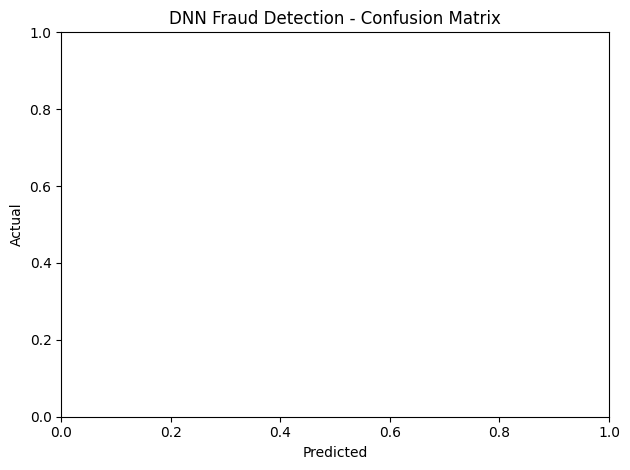

In [39]:

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DNN Fraud Detection - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300
)

plt.show()


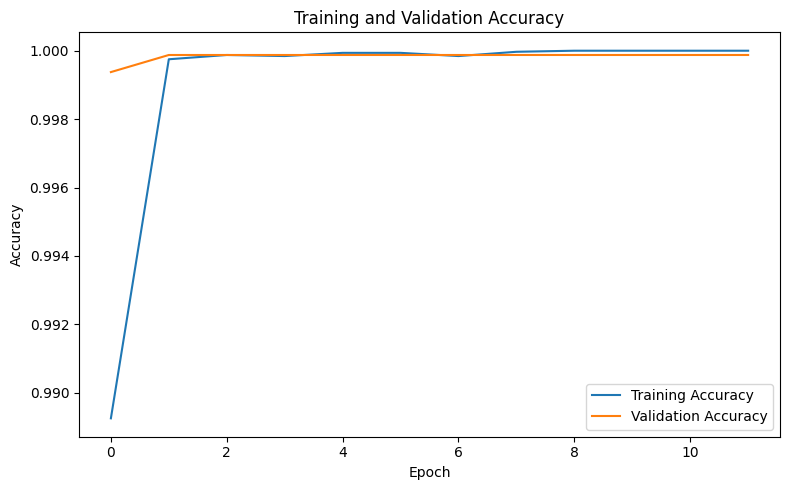

In [40]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()

plt.tight_layout()

plt.savefig(
    "accuracy_graph.png",
    dpi=300
)

plt.show()

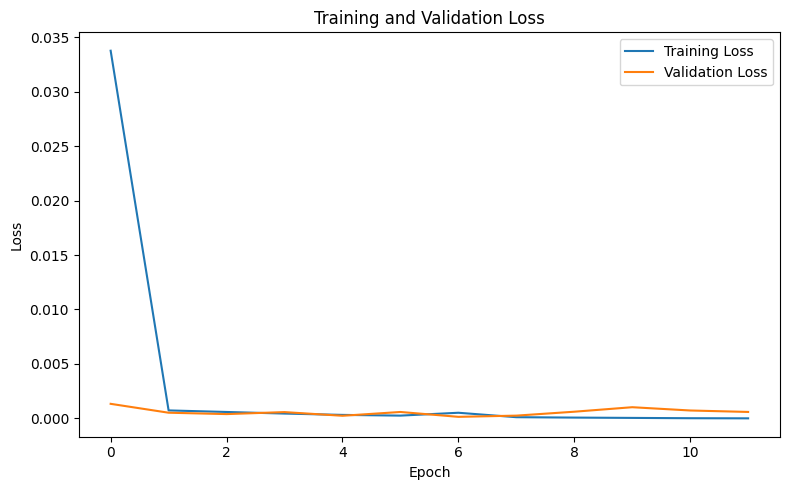

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()

plt.tight_layout()

plt.savefig(
    "loss_graph.png",
    dpi=300
)

plt.show()

In [42]:
def predict_fraud(
    hour_of_day,
    amount_usd,
    country,
    merchant,
    category,
    card_type,
    is_new_device,
    vpn_used,
    failed_attempts_24h,
    unusual_location,
    account_age_days,
    year,
    month,
    day,
    day_of_week
):

    new_transaction = pd.DataFrame({

        "hour_of_day": [hour_of_day],

        "amount_usd": [amount_usd],

        "country": [country],

        "merchant": [merchant],

        "category": [category],

        "card_type": [card_type],

        "is_new_device": [is_new_device],

        "vpn_used": [vpn_used],

        "failed_attempts_24h": [failed_attempts_24h],

        "unusual_location": [unusual_location],

        "account_age_days": [account_age_days],

        "year": [year],

        "month": [month],

        "day": [day],

        "day_of_week": [day_of_week]
    })


In [44]:
def predict_fraud(
    hour_of_day,
    amount_usd,
    country,
    merchant,
    category,
    card_type,
    is_new_device,
    vpn_used,
    failed_attempts_24h,
    unusual_location,
    account_age_days,
    year,
    month,
    day,
    day_of_week
):
    new_transaction = pd.DataFrame({
        "hour_of_day": [hour_of_day],
        "amount_usd": [amount_usd],
        "country": [country],
        "merchant": [merchant],
        "category": [category],
        "card_type": [card_type],
        "is_new_device": [is_new_device],
        "vpn_used": [vpn_used],
        "failed_attempts_24h": [failed_attempts_24h],
        "unusual_location": [unusual_location],
        "account_age_days": [account_age_days],
        "year": [year],
        "month": [month],
        "day": [day],
        "day_of_week": [day_of_week]
    })

    new_processed = preprocessor.transform(new_transaction)
    fraud_probability = model.predict(new_processed, verbose=0)[0, 0]
    fraud_prediction = int(fraud_probability >= 0.5)

    return {
        "probability": float(fraud_probability),
        "prediction": fraud_prediction,
        "label": "Fraud" if fraud_prediction == 1 else "Not Fraud"
    }

In [ ]:
sample = X.iloc[0].to_dict()

result = predict_fraud(
    hour_of_day=sample["hour_of_day"],
    amount_usd=sample["amount_usd"],
    country=sample["country"],
    merchant=sample["merchant"],
    category=sample["category"],
    card_type=sample["card_type"],
    is_new_device=sample["is_new_device"],
    vpn_used=sample["vpn_used"],
    failed_attempts_24h=sample["failed_attempts_24h"],
    unusual_location=sample["unusual_location"],
    account_age_days=sample["account_age_days"],
    year=sample["year"],
    month=sample["month"],
    day=sample["day"],
    day_of_week=sample["day_of_week"]
)

prediction = result["prediction"]
probability = result["probability"]

print("Prediction:", prediction)
print("Probability:", probability)


TypeError: predict_fraud() missing 14 required positional arguments: 'amount_usd', 'country', 'merchant', 'category', 'card_type', 'is_new_device', 'vpn_used', 'failed_attempts_24h', 'unusual_location', 'account_age_days', 'year', 'month', 'day', and 'day_of_week'